# This notebook calculates 0-D RE evolution during a Disruption

Loading modules

In [43]:
import sys
RE_path = './' # Path to RE.py -> This file contains required functions for calculating RE-relevant quantities
sys.path.insert(1, RE_path)

In [44]:
# Import other modules

import numpy as np
from matplotlib import pyplot as plt
import scipy.constants as const
from unit_conversion import *
import importlib
import RE 
importlib.reload(RE)
from RE import *

In [5]:
# Note: You can install missing module using pip install <module_name>
# For example, un-comment the next line to install numpy
#%pip install numpy

# Define Constants

In [68]:
importlib.reload(RE)
from RE import *

# Constants
R0 = 1.85 # Major Radius, [m]
a = 0.57 # Minor Radius, [m]
ni = 3e20 # ion density in plasma fuel, per m**3
L = 1.85e-6 # inductance [H]
k = 1 # elongation
Btor = 12.2 # Toroidal Field [Tesla]

# MGI ion densities
# If we have impurities, specify the impurity denisty here
nD = 1e-11 # Diuterium atoms
nNe = 1.5e20 # Neon (this was 1e-11 at first)

# Initial Conditions
I0 = 8.7e6 # [A], Initial Plasma Current

## Prescribe the TQ ##
# Here, we assume exponential decay from initial temperature T0 to final temperature Tf.
# (T0 - Tf)* np.exp(-t/t0) + Tf
T0 = 20e3 # eV, initial temperature (seems low?)
Tf = 10 # eV, final temperature
t0 = 0.1e-3 # TQ time [s]

# Print some relevant quantities
Umag = 0.5 * L * I0**2 # Initial magnetic energy, [J]
print('Initial magnetic energy [MJ] = %1.3g'%(Umag/1e6))


Initial magnetic energy [MJ] = 70


# Define the ODEs

The plasma and runaway current evolution is caluclated by solving this set of coupled ODEs.

Here, $I_p$ is the plasma current, $I_{RE}$ is the RE current, $E_\parallel$ is the parallel electric field, $\eta_\parallel(T)$ is the parallel resistivity, $R_0$ is the major radius, and $a$ is the minor radius. $d_t (I_{RE})_{primary}$ and $d_t (I_{RE})_{avalanche}$ are the primary and secondary avalnching rates.

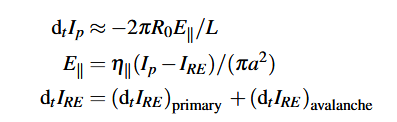

In [54]:
# Here we define the ODEs
def dYdt(t,Y,primary_sources=[1,1,1],iAvalanche=1,nD=1e-10,nNe=1e20):
    # Y[0] = Plasma Current [A]
    # Y[1] = RE current [A]
    # Y[2] = RE Kinetic Energy [J]
    # primary_sources = [iDreicer, iTritium, iCompton], 0 = off
    # iDreicer = 1 Classical; 2 = Hesslow NN
    # iAvalanche = 1 Rosenbluth-Putvinski * ntot/ne, 2 Simple RP, 3 = Hesslow, 0 = off
    
    Ip, Ir, Wkin = Y
    
    iDreicer, iTritium, iCompton = primary_sources
    
    # Prescribed Thermal Quench
    T = (T0 - Tf)* np.exp(-t/t0) + Tf # eV, Time-varying temperature
    # ZNe = getZbarTF(10, 20, SI2cgs(20*nNe*const.m_p,'Mass Density'), T)[0] # caluclate ionization level using LTE Thomas-Fermi model
    ZNe = getNeZ(T) # Using ADAS Coronal Eqm. Model
    ne = 1 * ni + 1 * nD + ZNe * nNe # Total free electron density, per cubic m, assumes hydrogenic species are fully ionized
    Zeff = (ni + nD + nNe * ZNe**2) / (ni + nD + nNe * ZNe) # Effective ionization of plasma
    ntot = ni + nD + 10 * nNe # Total free + bound electron density, per cubic m
    
    lnA = getCoulombLog(ne,T) # Coulomb logarithm
    eta = 0.51 * getTransSpitzerResistivity(lnA,T,Zeff) * 0.01 # Ohm-m
    Epar = eta*(Ip - Ir) / (np.pi * a**2 * k) # Parallel E-field [N/C]
    Ec = getConnorHastieField(ne,lnA) # Connor-Hastie Critical Field, [N/C]
    Ed = getDreicerField(ne,lnA,T) # [N/C] Dreicer Field
    E_star = Epar / Ec # Normalized field [-]
    
    
    # Primary Sources
    
    if iDreicer == 1:
        SD = getDreicerSource(E_star,ne,lnA,Zeff,T) # per m3 per s, Classical Dreicer
    elif iDreicer == 2:
        SD = getDreicerRateHesslow(ni,nNe,18,ZNe,Epar/Ed,T)
    else:
        SD = 0
    
    
    ST = getTritBetaDecay(0.5*ni,E_star)  # per m3 per s
    
    if T >= 2.6e3:
        SC = getComptonSource(E_star,ntot,'ARC-P') # Use Prompt Flux
    else:
        SC =  getComptonSource(E_star,ntot,'ARC-NP') # Use Non Prompt Flux
        
    # Total Primary Contribution
    S =  SD + iTritium * ST + iCompton * SC # per m3 per s
    j_primary = S * const.c * const.e # A/m**2/s
        
    # Avalanche
    if (iAvalanche == 0):
        Yav = 0;
    elif (iAvalanche == 1):
         Yav = (ntot/ne) * get_avalance_growth_rate_RP2(E_star,ne,0/R0,lnA,Zeff) # per second
    elif (iAvalanche == 2):
        Yav = 1 * get_avalance_growth_rate_RP2(E_star,ne,0/R0,lnA,Zeff) # per second
    elif (iAvalanche == 3): #Implement getHesslowAvalanchingRate 
     # Define arrays for species info, first element deuterium, second Neon (impurity)
        Z = np.array([1, 10])             # Max ionization of D and Ne
        nj = np.array([ni, nNe])          # Densities [m^-3]
        # trying to use interpolation here
        Zlow = int(np.floor(ZNe))
        Zhigh = int(np.ceil(ZNe))
        weight = ZNe - Zlow # interpolation weight

        # Creating 2 seperate arrays fo the low and high value
        Z0_low = np.array([1, Zlow])
        Z0_high = np.array([1, Zhigh])

        Y_low = getHesslowAvalanchingRate(E_star, Z, Z0_low, nj, T, element='Ne', B=Btor)
        Y_high = getHesslowAvalanchingRate(E_star, Z, Z0_high, nj, T, element='Ne', B=10)
        Yav = (1 - weight) * Y_low + weight * Y_high # set has the weighted average of the two
    
    dIpdt = -2 * np.pi * R0 * Epar / L # [A/s]
    dIrdt = j_primary * np.pi * a**2 + Yav * Ir # [A/s]
    if (E_star > 1):
        dWkindt = 2 * np.pi * R0 * Ir * Epar
    else:
        dWkindt = 0
    
    return [dIpdt, dIrdt, dWkindt]

# Solve

In [71]:
from scipy.integrate import solve_ivp
t = np.linspace(0,15e-3,10000) # times to solve at [s]

iDreicer, iTritium, iCompton = 0, 0, 0 # Set Primary Sources
iAvalanche = 3 # Set Avalanche Source
Ir0 = 1e3 # [A], Initial RE Current
primary_sources=[iDreicer, iTritium, iCompton] # [iDreicer, iTritium, iCompton]
sol = solve_ivp(dYdt, t_span=(0,max(t)), y0 = [I0,Ir0,0],t_eval=t,args=(primary_sources,iAvalanche,nD,nNe)) # Solve
print(sol)

  message: The solver successfully reached the end of the integration interval.
  success: True
   status: 0
        t: [ 0.000e+00  1.500e-06 ...  1.500e-02  1.500e-02]
        y: [[ 8.700e+06  8.700e+06 ...  6.986e+06  6.986e+06]
            [ 1.000e+03  1.000e+03 ...  6.985e+06  6.985e+06]
            [ 0.000e+00  0.000e+00 ...  2.795e+06  2.795e+06]]
      sol: None
 t_events: None
 y_events: None
     nfev: 170
     njev: 0
      nlu: 0


In [34]:
print(sol.t)
print(sol.y[0]) #Ip
print(sol.y[1]) #Re

[0.00000000e+00 1.50015002e-06 3.00030003e-06 ... 1.49969997e-02
 1.49984998e-02 1.50000000e-02]
[8700000.         8699999.63427302 8699998.93417986 ... 3038475.44991687
 3038474.23201103 3038473.01444068]
[1.00000000e-03 1.00000058e-03 1.00000229e-03 ... 3.03405417e+06
 3.03405417e+06 3.03405417e+06]


# Show Solution

Here, we will plot $I_p$ and $I_{RE}$ as a function of time

Plateau Current [MA] = 6.986


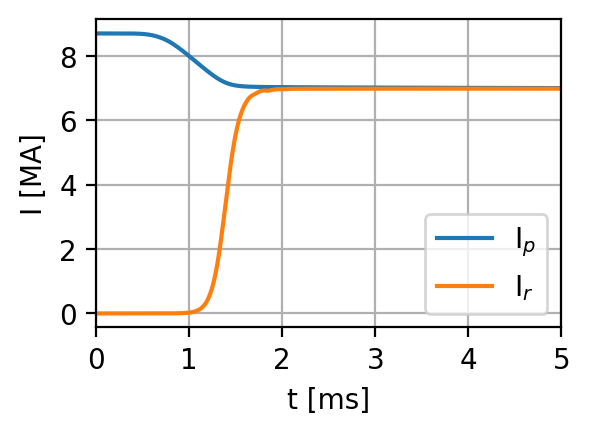

In [72]:
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=200,sharex=True)
axs.plot(sol.t*1e3,sol.y[0]/1e6,label='I$_p$')
axs.plot(sol.t*1e3,sol.y[1]/1e6,label='I$_r$')
axs.set_xlabel('t [ms]')
axs.set_ylabel('I [MA]')
axs.grid()
axs.set_yticks(np.arange(0,10,2))
axs.legend()
#axs.set_xlim([0,np.max(sol.t*1e3)])
axs.set_xlim([0,5])

print('Plateau Current [MA] = %1.3f'%(sol.y[0][-1]/1e6))


[np.float64(3.067311438734021), np.float64(3.6151244525030934), np.float64(4.1728077468062805), np.float64(4.727626509414402), np.float64(5.291368958934321), np.float64(5.856697430905011), np.float64(6.421168146782588), np.float64(6.991177134169944), np.float64(7.559729716278805)]


c:\Users\grace\OneDrive - Wellesley College\Desktop\UROP_Fall2025\RE_Solver\RE.py:784: RuntimeWarning: invalid value encountered in scalar power
  return pstar * (E_star)**(0.5) - (nuS * nuD)**(1/4)
c:\Users\grace\OneDrive - Wellesley College\Desktop\UROP_Fall2025\RE_Solver\RE.py:813: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  pstar = fsolve(fn, 1, args=(E_star,Z,Z0,nj,T,element))[0] # critical momentum [-]


[np.float64(4.696843582841305), np.float64(5.093201653692681), np.float64(5.486888349352661), np.float64(5.877052537158475), np.float64(6.267418021670067), np.float64(6.653456011583472), np.float64(7.039521696579307), np.float64(7.42217016769584), np.float64(7.805884979109419)]


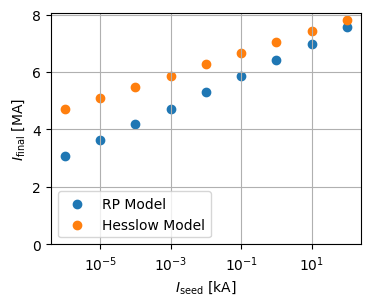

In [41]:
# Pick different I0s, change t the linspace, run and store final current values


from scipy.integrate import solve_ivp
t = np.linspace(0,15e-3,10000) # times to solve at [s]

iDreicer, iTritium, iCompton = 0, 0, 0 # Set Primary Sources
iAvalanche = 1 # Set Avalanche Source
#Ir0 = 1e-3 # [A], Initial RE Current
Iseed_values = np.logspace(-6, 2, 9)
primary_sources=[iDreicer, iTritium, iCompton] # [iDreicer, iTritium, iCompton]
#sol = solve_ivp(dYdt, t_span=(0,max(t)), y0 = [I0,Ir0,0],t_eval=t,args=(primary_sources,iAvalanche,nD,nNe)) # Solve
# print(sol)



  #kA
Ifinal_values = []

for Iseed_kA in Iseed_values:
    Ir0 = Iseed_kA * 1e3  # convert to A
    sol = solve_ivp(
        dYdt,
        t_span=(0, max(t)),
        y0=[I0, Ir0, 0],
        t_eval=t,
        args=(primary_sources, iAvalanche, nD, nNe),
    )
    Ifinal_values.append(sol.y[0][-1]/1e6)  # final RE current in MA
print(Ifinal_values)
# plot
plt.figure(figsize=(4,3))
plt.scatter(Iseed_values, Ifinal_values, label = 'RP Model')

Ifinal_values = []
iAvalanche = 3
for Iseed_kA in Iseed_values:
    Ir0 = Iseed_kA * 1e3  # convert to A
    sol = solve_ivp(
        dYdt,
        t_span=(0, max(t)),
        y0=[I0, Ir0, 0],
        t_eval=t,
        args=(primary_sources, iAvalanche, nD, nNe),
    )
    Ifinal_values.append(sol.y[0][-1]/1e6)  # final RE current in MA
print(Ifinal_values)
# plot
plt.scatter(Iseed_values, Ifinal_values, label = 'Hesslow Model')


plt.xscale('log')
plt.xlabel(r'$I_{\mathrm{seed}}$ [kA]')
plt.ylabel(r'$I_{\mathrm{final}}$ [MA]')
plt.yticks([0, 2, 4, 6, 8]) 
plt.grid()
plt.legend()
plt.show()

<>:52: SyntaxWarning: invalid escape sequence '\p'
<>:54: SyntaxWarning: invalid escape sequence '\p'
<>:63: SyntaxWarning: invalid escape sequence '\g'
<>:76: SyntaxWarning: invalid escape sequence '\,'
<>:52: SyntaxWarning: invalid escape sequence '\p'
<>:54: SyntaxWarning: invalid escape sequence '\p'
<>:63: SyntaxWarning: invalid escape sequence '\g'
<>:76: SyntaxWarning: invalid escape sequence '\,'
C:\Users\grace\AppData\Local\Temp\ipykernel_29416\11744234.py:52: SyntaxWarning: invalid escape sequence '\p'
  axs[2,0].plot(t*1e3,E_star,label='$E_{\parallel}/E_{CH}$')
C:\Users\grace\AppData\Local\Temp\ipykernel_29416\11744234.py:54: SyntaxWarning: invalid escape sequence '\p'
  axs[2,0].plot(t*1e3,Epar/Ed*1e5,label='$E_\parallel/E_D \\times 10^5$')
C:\Users\grace\AppData\Local\Temp\ipykernel_29416\11744234.py:63: SyntaxWarning: invalid escape sequence '\g'
  axs[0,1].set_ylabel('$\gamma_{ava}  [s^{-1}]$')
C:\Users\grace\AppData\Local\Temp\ipykernel_29416\11744234.py:76: SyntaxWarni

3264.4662811393086
max E/ED= 0.017356751317758917
max E/ECH= 871.1808062639687
Ed/ECH= 51099.89506917532
max SD=0
max SC=0
max ST==0


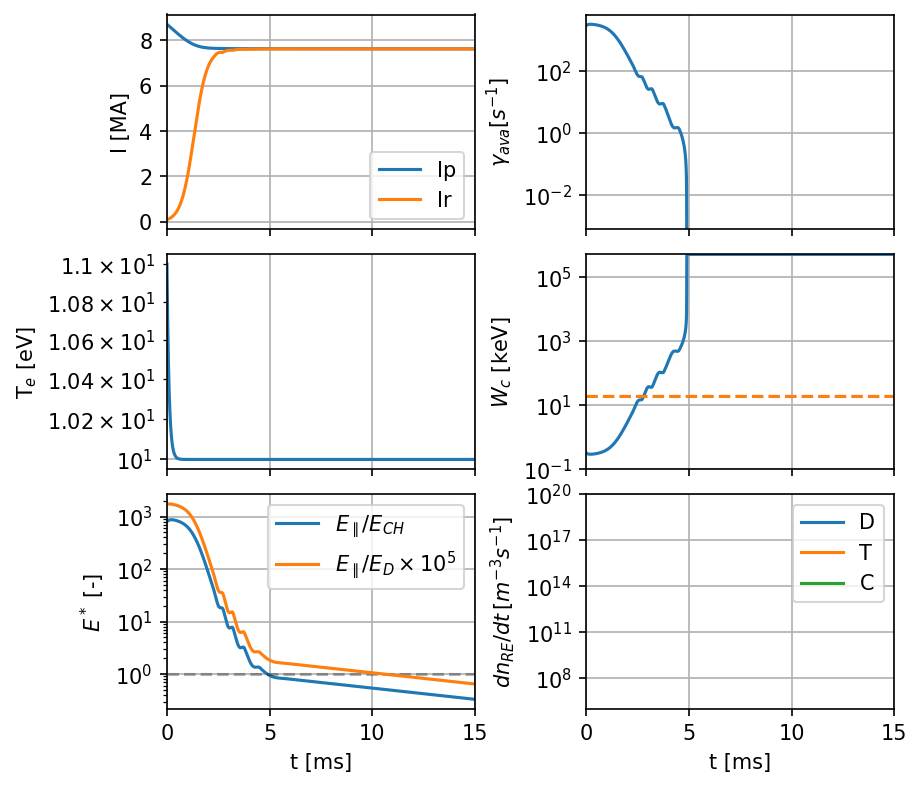

In [22]:
# Get Ip and Ir evolution from the ODE solution
Ip = sol.y[0]
Ir = sol.y[1]

# Calculate other relvant quantities
T = (T0 - Tf)* np.exp(-t/t0) + Tf # eV, Time-varying temperature
ZNe = getNeZ(T) # Using ADAS Coronal Eqm. Model
ne = 1 * ni + 1 * nD + ZNe * nNe # Total free electron density, per cubic m, assumes hydrogenic species are fully ionized
Zeff = (ni + nD + nNe * ZNe**2) / (ni + nD + nNe * ZNe) # Effective ionization of plasma
ntot = ni + nD + 10 * nNe # Total free + bound electron density, per cubic m
lnA = getCoulombLog(ne,T)
eta = 0.51 * getTransSpitzerResistivity(lnA,T,Zeff) * 0.01 # Ohm-m
Epar = eta*(Ip -Ir) / (np.pi * a**2 * k) # Parallel E-field [N/C]
Ec = getConnorHastieField(ne,lnA) # [N/C]
Ed = getDreicerField(ne,lnA,T) # [N/C]
E_star = Epar / Ec # Normalized field [-]
Wc = getCriticalRunawayEnergy(E_star) / const.eV # eV

# Primary Sources
if iDreicer == 1:
    SD = getDreicerSource(E_star,ne,lnA,Zeff,T) # per m3 per s, Classical Dreicer
elif iDreicer == 2:
    SD = getDreicerRateHesslow(ni,nNe,18,ZNe,Epar/Ed,T)
else:
    SD = np.zeros_like(E_star)

if iTritium:
    ST = getTritBetaDecay(0.5*ni,E_star)  # per m3 per s
else:
    ST = 0 * SD
if iCompton:
    SC =  getComptonSource(E_star,ntot,'ARC-P') 
    SC[np.where(T<2.6e3)] = 1e0 * getComptonSource(E_star[np.where(T<2.6e3)],ntot,'ARC-NP') 
else:
    SC = 0 * SD

# Secondary Sources
Yav =  (ntot / ne) * get_avalance_growth_rate_RP2(E_star,ne,0/R0,lnA,Zeff) # per second

############ Plot ##################
fig, axs = plt.subplots(3,2,sharex=True,figsize=(6,5),dpi=150)

axs[0,0].plot(t*1e3,Ip/1e6,label='Ip')
axs[0,0].plot(t*1e3,Ir/1e6,label='Ir')
axs[0,0].set_ylabel('I [MA]')
axs[0,0].legend()

axs[1,0].plot(t*1e3,T)
axs[1,0].set_ylabel('T$_e$ [eV]')
axs[1,0].set_yscale('log')

axs[2,0].plot(t*1e3,E_star,label='$E_{\parallel}/E_{CH}$')
axs[2,0].plot([0,t.max()*1e3],[1,1],'--',color='k',alpha=0.3)
axs[2,0].plot(t*1e3,Epar/Ed*1e5,label='$E_\parallel/E_D \\times 10^5$')
axs[2,0].set_ylabel('$E^*$ [-]')
axs[2,0].set_yscale('log')
axs[2,0].legend()



axs[0,1].plot(t*1e3,Yav)
print(np.max(Yav))
axs[0,1].set_ylabel('$\gamma_{ava}  [s^{-1}]$')
axs[0,1].set_yscale('log')

axs[1,1].plot(t*1e3,Wc/1e3)
axs[1,1].plot(t*1e3,18.7*np.ones_like(t),'--')
axs[1,1].set_ylabel('$W_c$ [keV]')
axs[1,1].set_yscale('log')
axs[1,1].set_ylim([1e-1,1e4])
axs[1,1].set_ylim(ymax=getCriticalRunawayEnergy(1) / const.eV / 1e3)

axs[2,1].plot(t*1e3,SD,label='D')
axs[2,1].plot(t*1e3,ST,label='T')
axs[2,1].plot(t*1e3,SC,label='C')
axs[2,1].set_ylabel('$dn_{RE}/dt \, [m^{-3}s^{-1}]$')
axs[2,1].set_yscale('log')
axs[2,1].set_ylim([1e6,1e20])
axs[2,1].legend()


fig.tight_layout(pad=0.5)

for i in range(axs.shape[0]):
    for j in range(axs.shape[1]):
        axs[i,j].grid()
        axs[i,j].set_xlim([0,np.max(t*1e3)])
        
axs[-1,0].set_xlabel('t [ms]')    
axs[-1,1].set_xlabel('t [ms]')  

# Print Max Values #
print('max E/ED=',np.max(Epar/Ed))
print('max E/ECH=',np.max(E_star))
print('Ed/ECH=',np.max(Ed/Ec))
print('max SD=%1.3g'%np.max(SD))
print('max SC=%1.3g'%np.max(SC))
print('max ST==%1.3g'%np.max(ST))

C:\Users\grace\AppData\Local\Temp\ipykernel_61764\3696301729.py:11: RuntimeWarning: overflow encountered in exp
  return I0 * np.exp(gamma * t) # + I0  # Ire current value


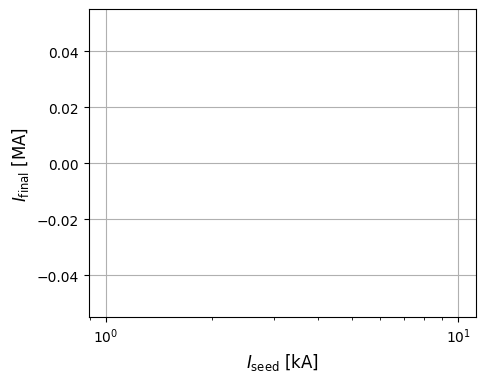

In [94]:
# analytical solution
gamma = 3348      # avalanche growth rate [1/s] (was there a value for this i forget)
t_final = 10   # final time [s]

# seed currents in kA (log-spaced from 1e-6 to 1e2)
I0_kA = np.logspace(-6, 2, 10)
I0_A = I0_kA * 1e3   # convert to A

# solution to constant avalanching rate, no primary generation, and initial RE current I0
def Ire(I0, gamma, t):
    return I0 * np.exp(gamma * t) # + I0  # Ire current value

# compute final currents
Ifinal_A = Ire(I0_A, gamma, t_final)
Ifinal_MA = Ifinal_A / 1e6  # convert to MA

# show
plt.figure(figsize=(5,4))
plt.scatter(I0_kA, Ifinal_MA)
plt.xscale('log')
plt.xlabel(r'$I_{\mathrm{seed}}$ [kA]', fontsize=12)
plt.ylabel(r'$I_{\mathrm{final}}$ [MA]', fontsize=12)
plt.grid()
plt.show()




[1.00000000e+00 1.00301286e+00 1.00603863e+00 ... 4.87327353e+06
 4.87328415e+06 4.87329475e+06]
[ 1.          1.03439652  1.06997616  1.10677961  1.14484897  1.18422779
  1.2249611   1.2670955   1.31067917  1.35576197  1.40239546  1.45063298
  1.5005297   1.5521427   1.605531    1.66075568  1.71787989  1.77696898
  1.83809052  1.90131443  1.96671303  2.03436111  2.10433605  2.17671788
  2.25158939  2.32903623  2.40914696  2.49201323  2.5777298   2.66639473
  2.75810943  2.85297879  2.95111132  3.05261927  3.15761874  3.26622983
  3.37857677  3.49478804  3.61499658  3.73933987  3.86796014  4.0010045
  4.13862512  4.28097941  4.4282302   4.58054589  4.73810072  4.90107489
  5.06965479  5.24403326  5.42440975  5.61099055  5.80398909  6.0036261
  6.21012993  6.42373677  6.64469095  6.87324517  7.10966087  7.35420845
  7.60716761  7.86882768  8.13948795  8.41945799  8.70905803  9.00861929
  9.31848442  9.63900784  9.97055614 10.31350855 10.66825733 11.03520823
 11.41478096 11.80740967 12.2

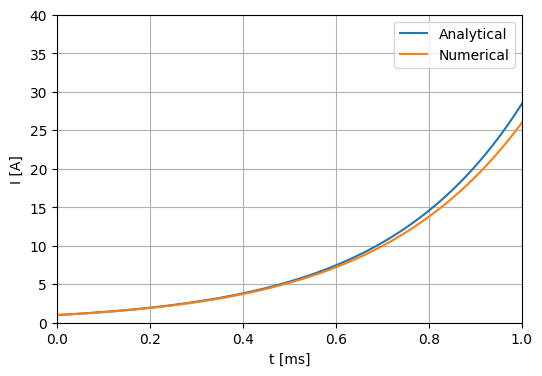

In [96]:
fig = plt.figure(figsize=(6,4))

gamma = 3348
t = np.linspace(0, 1e-3, 100)
I0 = 1

I = Ire(I0, gamma, t)
plt.plot(t*1000, I, label = 'Analytical')




plt.plot(sol.t*1000, sol.y[1], label = 'Numerical')
print(sol.y[1])
print(I)
plt.xlim(0, 1)
plt.ylim(0, 40)
plt.legend()
plt.xlabel("t [ms]")
plt.ylabel("I [A]")
plt.grid()
plt.show()

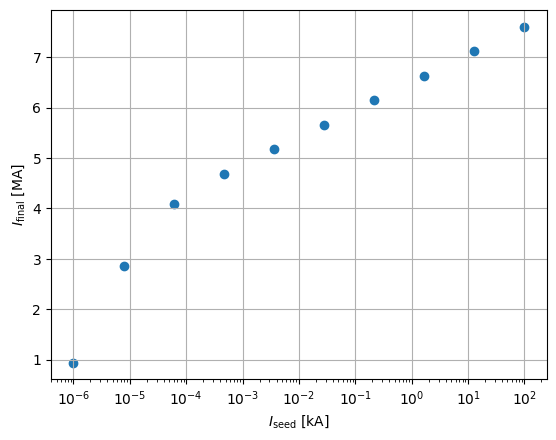

In [58]:

iDreicer, iTritium, iCompton = 0, 0, 0
iAvalanche = 1
primary_sources = [iDreicer, iTritium, iCompton]
t = np.linspace(0, 10e-3, 2000)

# vary seed RE current
Iseed_values = np.logspace(-6, 2, 10)  #kA
Ifinal_values = []

for Iseed_kA in Iseed_values:
    Ir0 = Iseed_kA * 1e3  # convert to A
    sol = solve_ivp(
        dYdt,
        t_span=(0, max(t)),
        y0=[I0, Ir0, 0],
        t_eval=t,
        args=(primary_sources, iAvalanche, nD, nNe),
        rtol=1e-6, atol=1e-9
    )
    Ifinal_values.append(sol.y[1, -1] / 1e6)  # final RE current in MA

# plot
plt.scatter(Iseed_values, Ifinal_values)
plt.xscale('log')
plt.xlabel(r'$I_{\mathrm{seed}}$ [kA]')
plt.ylabel(r'$I_{\mathrm{final}}$ [MA]')
plt.grid()
plt.show()



# RE Energy
We can also plot the RE beam energy as a function of time

Plateau Energy [MJ] = 3.460
Average RE Energy [MeV] = 11.727


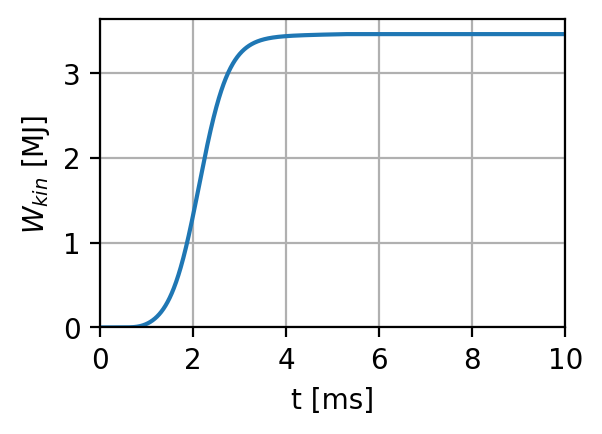

In [59]:
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=200,sharex=True)
axs.plot(sol.t*1e3,sol.y[2]/1e6)
axs.set_xlabel('t [ms]')
axs.set_ylabel('$W_{kin}$ [MJ]')
axs.grid()
axs.set_ylim(ymin=0)
axs.set_xlim([0,np.max(sol.t*1e3)])
# axs.set_yscale('log')

print('Plateau Energy [MJ] = %1.3f'%(sol.y[2][-1]/1e6))

# Estimate the average Re energy in MeV
N = sol.y[1][-1] * (2 * np.pi * R0) / (const.e * const.c)
avg_energy = sol.y[2][-1] / N
print('Average RE Energy [MeV] = %1.3f'%(avg_energy/1e6/const.eV))

# Show detailed results

<>:52: SyntaxWarning: invalid escape sequence '\p'
<>:54: SyntaxWarning: invalid escape sequence '\p'
<>:62: SyntaxWarning: invalid escape sequence '\g'
<>:75: SyntaxWarning: invalid escape sequence '\,'
<>:52: SyntaxWarning: invalid escape sequence '\p'
<>:54: SyntaxWarning: invalid escape sequence '\p'
<>:62: SyntaxWarning: invalid escape sequence '\g'
<>:75: SyntaxWarning: invalid escape sequence '\,'
C:\Users\grace\AppData\Local\Temp\ipykernel_61764\821247975.py:52: SyntaxWarning: invalid escape sequence '\p'
  axs[2,0].plot(t*1e3,E_star,label='$E_{\parallel}/E_{CH}$')
C:\Users\grace\AppData\Local\Temp\ipykernel_61764\821247975.py:54: SyntaxWarning: invalid escape sequence '\p'
  axs[2,0].plot(t*1e3,Epar/Ed*1e5,label='$E_\parallel/E_D \\times 10^5$')
C:\Users\grace\AppData\Local\Temp\ipykernel_61764\821247975.py:62: SyntaxWarning: invalid escape sequence '\g'
  axs[0,1].set_ylabel('$\gamma_{ava}  [s^{-1}]$')
C:\Users\grace\AppData\Local\Temp\ipykernel_61764\821247975.py:75: SyntaxW

ValueError: x and y must have same first dimension, but have shapes (1,) and (2000,)

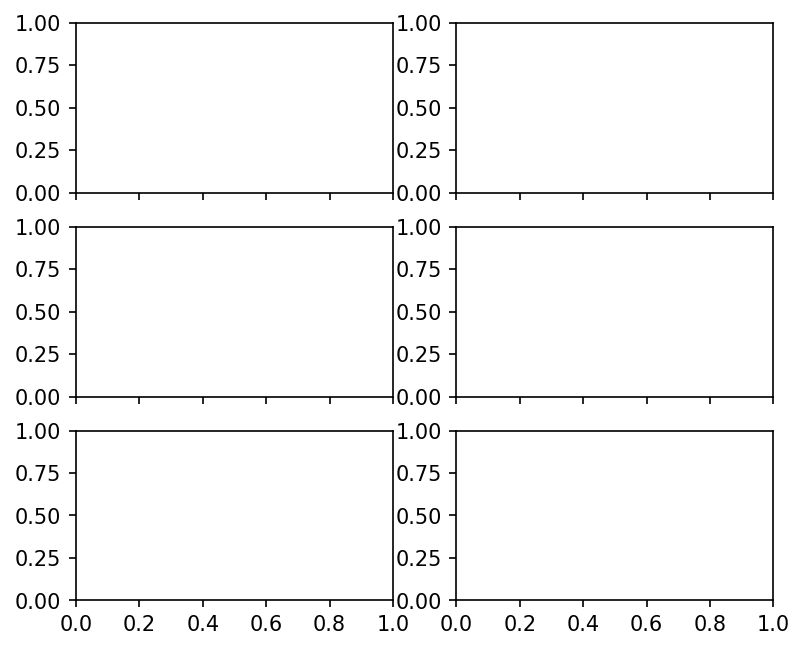

In [48]:
# Get Ip and Ir evolution from the ODE solution
Ip = sol.y[0]
Ir = sol.y[1]

# Calculate other relvant quantities
T = (T0 - Tf)* np.exp(-t/t0) + Tf # eV, Time-varying temperature
ZNe = getNeZ(T) # Using ADAS Coronal Eqm. Model
ne = 1 * ni + 1 * nD + ZNe * nNe # Total free electron density, per cubic m, assumes hydrogenic species are fully ionized
Zeff = (ni + nD + nNe * ZNe**2) / (ni + nD + nNe * ZNe) # Effective ionization of plasma
ntot = ni + nD + 10 * nNe # Total free + bound electron density, per cubic m
lnA = getCoulombLog(ne,T)
eta = 0.51 * getTransSpitzerResistivity(lnA,T,Zeff) * 0.01 # Ohm-m
Epar = eta*(Ip -Ir) / (np.pi * a**2 * k) # Parallel E-field [N/C]
Ec = getConnorHastieField(ne,lnA) # [N/C]
Ed = getDreicerField(ne,lnA,T) # [N/C]
E_star = Epar / Ec # Normalized field [-]
Wc = getCriticalRunawayEnergy(E_star) / const.eV # eV

# Primary Sources
if iDreicer == 1:
    SD = getDreicerSource(E_star,ne,lnA,Zeff,T) # per m3 per s, Classical Dreicer
elif iDreicer == 2:
    SD = getDreicerRateHesslow(ni,nNe,18,ZNe,Epar/Ed,T)
else:
    SD = np.zeros_like(E_star)

if iTritium:
    ST = getTritBetaDecay(0.5*ni,E_star)  # per m3 per s
else:
    ST = 0 * SD
if iCompton:
    SC =  getComptonSource(E_star,ntot,'ARC-P') 
    SC[np.where(T<2.6e3)] = 1e0 * getComptonSource(E_star[np.where(T<2.6e3)],ntot,'ARC-NP') 
else:
    SC = 0 * SD

# Secondary Sources
Yav =  (ntot / ne) * get_avalance_growth_rate_RP2(E_star,ne,0/R0,lnA,Zeff) # per second

############ Plot ##################
fig, axs = plt.subplots(3,2,sharex=True,figsize=(6,5),dpi=150)

axs[0,0].plot(t*1e3,Ip/1e6,label='Ip')
axs[0,0].plot(t*1e3,Ir/1e6,label='Ir')
axs[0,0].set_ylabel('I [MA]')
axs[0,0].legend()

axs[1,0].plot(t*1e3,T)
axs[1,0].set_ylabel('T$_e$ [eV]')
axs[1,0].set_yscale('log')

axs[2,0].plot(t*1e3,E_star,label='$E_{\parallel}/E_{CH}$')
axs[2,0].plot([0,t.max()*1e3],[1,1],'--',color='k',alpha=0.3)
axs[2,0].plot(t*1e3,Epar/Ed*1e5,label='$E_\parallel/E_D \\times 10^5$')
axs[2,0].set_ylabel('$E^*$ [-]')
axs[2,0].set_yscale('log')
axs[2,0].legend()



axs[0,1].plot(t*1e3,Yav)
axs[0,1].set_ylabel('$\gamma_{ava}  [s^{-1}]$')
axs[0,1].set_yscale('log')

axs[1,1].plot(t*1e3,Wc/1e3)
axs[1,1].plot(t*1e3,18.7*np.ones_like(t),'--')
axs[1,1].set_ylabel('$W_c$ [keV]')
axs[1,1].set_yscale('log')
axs[1,1].set_ylim([1e-1,1e4])
axs[1,1].set_ylim(ymax=getCriticalRunawayEnergy(1) / const.eV / 1e3)

axs[2,1].plot(t*1e3,SD,label='D')
axs[2,1].plot(t*1e3,ST,label='T')
axs[2,1].plot(t*1e3,SC,label='C')
axs[2,1].set_ylabel('$dn_{RE}/dt \, [m^{-3}s^{-1}]$')
axs[2,1].set_yscale('log')
axs[2,1].set_ylim([1e6,1e20])
axs[2,1].legend()


fig.tight_layout(pad=0.5)

for i in range(axs.shape[0]):
    for j in range(axs.shape[1]):
        axs[i,j].grid()
        axs[i,j].set_xlim([0,np.max(t*1e3)])
        
axs[-1,0].set_xlabel('t [ms]')    
axs[-1,1].set_xlabel('t [ms]')  

# Print Max Values #
print('max E/ED=',np.max(Epar/Ed))
print('max E/ECH=',np.max(E_star))
print('Ed/ECH=',np.max(Ed/Ec))
print('max SD=%1.3g'%np.max(SD))
print('max SC=%1.3g'%np.max(SC))
print('max ST==%1.3g'%np.max(ST))